# Notebook 6 — Relative-value research: is the autoencoder residual a tradable mispricing?

**Research question.** The CVAE reconstructs curves from two latent factors. When the market curve
deviates from its reconstruction, is that deviation a **mispricing that mean-reverts in price**
(tradable), or simply a **model error** that disappears because the model, not the market, moves?

We answer it with three experiments, all strictly out of sample:

| § | Experiment | What would support "tradable mispricing" |
|---|---|---|
| 2 | Predictive power of residuals at 1/5/10/20 days, per tenor and per hedged package, against PCA and Nelson–Siegel (NS); dynamic NS enters in §5 as a forecasting benchmark | Negative and significant correlation between today's residual and the *factor-hedged* future move, stronger for the VAE than for linear models |
| 3 | Hedged-package portfolios with a full P&L decomposition (rates, carry, rolldown, costs) and residual alpha after removing the known level/slope/curvature exposure | Positive net Sharpe that survives costs and is not explained by factor exposure |
| 4 | Regime dependence: Markov-switching on the VAE latent factors, **filtered** probabilities only | Different mean-reversion speed / IC across volatility regimes, and better net results when trading is conditioned on the regime |
| 5 | Training objective: reconstruction vs prediction vs multitask | A model trained to predict produces better trading signals than one trained to reconstruct |

**Timeline (no look-ahead).** All models and factor loadings are fitted on **2020-09-09 → 2023-12-31**.
Evaluation runs on **2024-01-01 → 2026-10-23** (≈ 735 business days, all out of sample). Signal
z-scores use only evaluation-period history up to the decision date. Regime probabilities are
*filtered* (they use data up to t), never smoothed. Parameters are set in §0 and not optimised on
evaluation-period results.

Scope: HJM / no-arbitrage constrained models and FX-hedged cross-currency trades were considered and
left out — the former is a pricing project in its own right with no alpha question, the latter is
already covered by NB4 (Extension 2).

## 0 — Setup

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import torch
import torch.nn as nn
import torch.optim as optim
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (14, 6), "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})

SEED = 42
TENORS = [2, 3, 5, 10, 15, 20, 30]
S_MIN, S_MAX = -0.05, 0.25
BP = 1e4
FIT_END = pd.Timestamp("2023-12-31")
EVAL_START = pd.Timestamp("2024-01-01")
HORIZONS = [1, 5, 10, 20]

P = dict(
    Z_WINDOW=250, Z_MIN=60,      # causal z-score of signals (evaluation-period history only)
    SIGNAL_CAP=3.0,              # positions proportional to the z-score, capped at ±3
    VOL_WINDOW=60, TARGET_VOL_BP=1.0,   # each package position targets 1 bp/day of P&L volatility at |z| = 1
    EXEC_DELAY=1,                # decision at close t, filled at close t+1
    REBAL=5,                     # rebalance weekly (every 5 business days)
    TC_LEG_BP=0.25,              # cost per leg per unit DV01 (half bid/offer), on every change of position
    POSTPROC_STEPS=500,          # Sokol §2.3.1 post-processing (converged, see NB5)
    PRED_H=[5, 20],              # horizons predicted by the prediction / multitask models
    PRED_EPOCHS=3000, MTL_REC_SCALE=1e-5, MTL_WEIGHT=1.0, RIDGE_ALPHA=10.0,
)
torch.manual_seed(SEED); np.random.seed(SEED)

In [2]:
df_long = pd.read_csv("data/df_multi.csv", parse_dates=["Date"])
CURRENCIES = sorted(df_long["currency"].unique()); N_CCY = len(CURRENCIES)
CCY_IDX = {c: i for i, c in enumerate(CURRENCIES)}
curves = {c: g.set_index("Date").sort_index()[[str(t) for t in TENORS]].set_axis(TENORS, axis=1)
          for c, g in df_long.groupby("currency")}                     # decimal par swap rates
dates = curves[CURRENCIES[0]].index
fit_mask = dates <= FIT_END
eval_mask = dates >= EVAL_START

# 1Y tenor (rolldown of the 2Y point) and floating-leg fixings (carry)
SHEETS = {"USD": ("USD_USOSFR", "USOSFR"), "EUR": ("EUR_EESWE", "EESWE"), "GBP": ("GBP_BPSWS", "BPSWS"),
          "JPY": ("JPY_JYSO", "JYSO"), "AUD": ("AUD_ADSO", "ADSO"), "CAD": ("CAD_CDSO", "CDSO"),
          "CHF": ("CHF_SFSNT", "SFSNT"), "DKK": ("DKK_DKSW", "DKSW"), "CZK": ("CZK_CKSWO", "CKSW")}
FLOAT = {"USD": ("OVERNIGHT", "SOFRRATE Index"), "EUR": ("OVERNIGHT", "ESTRON Index"),
         "GBP": ("OVERNIGHT", "SONIO/N Index"), "JPY": ("OVERNIGHT", "MUTKCALM Index"),
         "AUD": ("OVERNIGHT", "RBACOR Index"), "CAD": ("OVERNIGHT", "CAONREPO Index"),
         "CHF": ("OVERNIGHT", "SSARON Index"),
         "DKK": ("FIXINGS_RISK", "CIBO06M Index"), "CZK": ("FIXINGS_RISK", "PRIB06M Index")}


def to_dates(s: pd.Series) -> pd.Series:
    s = pd.to_numeric(s, errors="coerce")
    s.index = pd.to_datetime(s.index, errors="coerce")
    s = s[s.index.notna()].sort_index()
    s = s[~s.index.duplicated()]
    return s.reindex(s.index.union(dates)).ffill(limit=10).reindex(dates)


def read_sheet(path, sheet):
    d = pd.read_excel(path, sheet_name=sheet)
    return d.set_index(d.columns[0])


xl = "data/bloomberg_swap_download_comlet.xlsx"
one_y = {c: to_dates(read_sheet(xl, SHEETS[c][0])[f"{SHEETS[c][1]}1 Curncy"]) / 100 for c in CURRENCIES}
src = {"OVERNIGHT": read_sheet("data/bloomberg_extras_overnight_comlet.xlsx", "OVERNIGHT"),
       "FIXINGS_RISK": read_sheet("data/bloomberg_extras_fixings_vols_comlet.xlsx", "FIXINGS_RISK")}
floating = {c: to_dates(src[FLOAT[c][0]][FLOAT[c][1]]) / 100 for c in CURRENCIES}

cov = pd.DataFrame({"1Y available": {c: one_y[c].notna().mean() for c in CURRENCIES},
                    "floating index": {c: FLOAT[c][1] for c in CURRENCIES},
                    "floating available": {c: floating[c].notna().mean() for c in CURRENCIES}})
print(f"{N_CCY} currencies, fit {fit_mask.sum()} days (≤ {FIT_END.date()}), evaluation {eval_mask.sum()} days "
      f"({dates[eval_mask][0].date()} → {dates[-1].date()})")
cov

9 currencies, fit 863 days (≤ 2023-12-31), evaluation 735 days (2024-01-01 → 2026-10-23)


,1Y available,floating index,floating available
AUD,1.0,RBACOR Index,1.0
CAD,1.0,CAONREPO Index,1.0
CHF,1.0,SSARON Index,1.0
CZK,1.0,PRIB06M Index,1.0
DKK,1.0,CIBO06M Index,1.0
EUR,1.0,ESTRON Index,1.0
GBP,1.0,SONIO/N Index,1.0
JPY,1.0,MUTKCALM Index,1.0
USD,1.0,SOFRRATE Index,1.0


## 1 — Fair-value and forecasting models (fitted on 2020–2023 only)

| Model | Type | Output used |
|---|---|---|
| **VAE** | CVAE (Sokol Table 3) + post-processing gradient descent (§2.3.1) | residual $r = S - S'$ |
| **PCA-2 / PCA-3** | per-currency principal components of curve *levels* | residual |
| **NS** | Nelson–Siegel, λ by pooled grid search (in-sample fit) on the fit window | residual |
| **DNS** | dynamic NS: VAR(1) on the NS betas | forecast of the curve move (factor dynamics only) |

The CVAE weights are shared with NB5 (same architecture, fit window and seed) and trained here if NB5
has not been run.

In [3]:
def normalize(r):
    return np.clip((r - S_MIN) / (S_MAX - S_MIN), 0.0, 1.0)


def denormalize(x):
    return x * (S_MAX - S_MIN) + S_MIN


def one_hot(ccy, n):
    y = np.zeros((n, N_CCY), dtype=np.float32); y[:, CCY_IDX[ccy]] = 1.0
    return torch.from_numpy(y)


class MultiHeadCVAE(nn.Module):
    """CVAE encoder (Sokol Table 3) with an optional reconstruction decoder and an optional prediction head.

    recon=True, pred=False is exactly the CVAE of NB3/NB5."""
    def __init__(self, recon=True, pred=False, input_dim=7, latent_dim=2, n_ccy=N_CCY, n_pred=7 * len(P["PRED_H"])):
        super().__init__()
        self.latent_dim, self.has_recon, self.has_pred = latent_dim, recon, pred
        enc_in, dec_in = input_dim + n_ccy, latent_dim + n_ccy
        self.encoder = nn.Sequential(nn.Linear(enc_in, enc_in - 1), nn.Tanh(), nn.Linear(enc_in - 1, 2 * latent_dim))
        if recon:
            self.decoder = nn.Sequential(nn.Linear(dec_in, input_dim), nn.Tanh(), nn.Linear(input_dim, input_dim), nn.Tanh(),
                                         nn.Linear(input_dim, input_dim), nn.Sigmoid())
        if pred:
            self.pred_head = nn.Sequential(nn.Linear(dec_in, 16), nn.Tanh(), nn.Linear(16, 16), nn.Tanh(), nn.Linear(16, n_pred))

    def encode(self, x, y):
        h = self.encoder(torch.cat([x, y], -1))
        return h[:, :self.latent_dim], h[:, self.latent_dim:]

    def decode(self, z, y):
        return self.decoder(torch.cat([z, y], -1))

    def predict(self, z, y):
        return self.pred_head(torch.cat([z, y], -1))

    def forward(self, x, y):
        mu, lv = self.encode(x, y)
        z = mu + torch.exp(0.5 * lv) * torch.randn_like(mu) if self.training else mu
        rec = self.decode(z, y) if self.has_recon else None
        prd = self.predict(z, y) if self.has_pred else None
        return rec, prd, mu, lv


def train_model(model, X, Y, T=None, n_epochs=5000, batch_size=256, lr=1e-3, beta=1e-7):
    """Adam + ReduceLROnPlateau + clipping (as NB3). T = standardised prediction targets (optional)."""
    opt = optim.Adam(model.parameters(), lr=lr)
    sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", patience=500, factor=0.5, min_lr=1e-6)
    tensors = (X, Y) if T is None else (X, Y, T)
    loader = DataLoader(TensorDataset(*tensors), batch_size=batch_size, shuffle=True)
    for ep in range(1, n_epochs + 1):
        model.train(); tot = 0.0
        for b in loader:
            xb, yb = b[0], b[1]
            rec, prd, mu, lv = model(xb, yb)
            loss = beta * torch.mean(-0.5 * torch.sum(1 + lv - mu.pow(2) - torch.exp(lv), -1))
            if rec is not None:
                rl = torch.mean(torch.sum((rec - xb) ** 2, -1))
                loss = loss + (rl / P["MTL_REC_SCALE"] if prd is not None else rl)
            if prd is not None:
                loss = loss + P["MTL_WEIGHT"] * torch.mean((prd - b[2]) ** 2)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += float(loss.detach())
        sched.step(tot / len(loader))
        if ep == 1 or ep % 1000 == 0:
            print(f"  epoch {ep:>5d}  loss {tot / len(loader):.3e}")
    model.eval()
    return model


X_fit = torch.from_numpy(np.vstack([normalize(curves[c].loc[fit_mask].values) for c in CURRENCIES]).astype(np.float32))
Y_fit = torch.cat([one_hot(c, int(fit_mask.sum())) for c in CURRENCIES])

cvae_path = RES_DIR / f"nb5_cvae_fit_{FIT_END.date()}_{N_CCY}ccy.pt"     # shared with NB5
cvae = MultiHeadCVAE(recon=True, pred=False)
if cvae_path.exists():
    cvae.load_state_dict(torch.load(cvae_path)); cvae.eval(); print(f"VAE: loaded {cvae_path}")
else:
    print("VAE: training on the fit window…"); torch.manual_seed(SEED)
    train_model(cvae, X_fit, Y_fit); torch.save(cvae.state_dict(), cvae_path)


def postprocess(model, x, y, steps=P["POSTPROC_STEPS"], lr=0.01):
    with torch.no_grad():
        mu, _ = model.encode(x, y)
    z = mu.clone().requires_grad_(True); opt = optim.Adam([z], lr=lr)
    for _ in range(steps):
        opt.zero_grad(); loss = torch.mean(torch.sum((model.decode(z, y) - x) ** 2, -1)); loss.backward(); opt.step()
    with torch.no_grad():
        return z.detach().numpy(), denormalize(model.decode(z, y).numpy())


resid, z_star = {m: {} for m in ["VAE", "PCA-2", "PCA-3", "NS"]}, {}
for c in CURRENCIES:
    x = torch.from_numpy(normalize(curves[c].values).astype(np.float32))
    z_star[c], rec = postprocess(cvae, x, one_hot(c, len(x)))
    resid["VAE"][c] = (curves[c] - rec) * BP

# PCA on curve levels (fit window)
for c in CURRENCIES:
    S = curves[c].values; mu = S[fit_mask].mean(0)
    Vt = np.linalg.svd(S[fit_mask] - mu, full_matrices=False)[2]
    for k in (2, 3):
        V = Vt[:k].T
        resid[f"PCA-{k}"][c] = pd.DataFrame((S - (mu + (S - mu) @ V @ V.T)) * BP, index=dates, columns=TENORS)

# Nelson-Siegel (lambda by pooled CV on the fit window) and dynamic NS (VAR(1) on betas)
tau = np.array(TENORS, dtype=float)


def ns_basis(lam):
    lt = lam * tau; f1 = (1 - np.exp(-lt)) / lt
    return np.column_stack([np.ones_like(tau), f1, f1 - np.exp(-lt)])


fit_rates = np.vstack([curves[c].loc[fit_mask].values for c in CURRENCIES])
cv = {lam: np.sqrt(((fit_rates - (ns_basis(lam) @ np.linalg.lstsq(ns_basis(lam), fit_rates.T, rcond=None)[0]).T) ** 2)
                   .mean(1)).mean() for lam in np.linspace(0.05, 2.0, 40)}
LAM = min(cv, key=cv.get); B_NS = ns_basis(LAM)
betas, var1 = {}, {}
for c in CURRENCIES:
    b = np.linalg.lstsq(B_NS, curves[c].values.T, rcond=None)[0].T            # (T, 3)
    betas[c] = b
    resid["NS"][c] = pd.DataFrame((curves[c].values - b @ B_NS.T) * BP, index=dates, columns=TENORS)
    bf = b[fit_mask]
    Xv = np.column_stack([np.ones(len(bf) - 1), bf[:-1]])
    coef = np.linalg.lstsq(Xv, bf[1:], rcond=None)[0]                         # (4, 3)
    var1[c] = dict(c=coef[0], A=coef[1:].T)
print(f"NS lambda (fit-window CV) = {LAM:.3f}")

rmse = pd.DataFrame({m: {c: np.sqrt((resid[m][c][eval_mask] ** 2).mean(axis=1)).mean() for c in CURRENCIES}
                     for m in resid})
print("Evaluation-period reconstruction RMSE (bp) — models fitted on 2020–2023:")
rmse.round(2)

VAE: loaded results/nb5_cvae_fit_2023-12-31_9ccy.pt


NS lambda (fit-window CV) = 0.450
Evaluation-period reconstruction RMSE (bp) — models fitted on 2020–2023:


,VAE,PCA-2,PCA-3,NS
AUD,10.03,9.36,8.49,7.72
CAD,6.99,5.41,2.92,5.63
CHF,5.90,3.10,1.74,3.03
CZK,5.06,5.85,3.39,2.92
DKK,10.18,10.52,3.60,5.79
EUR,7.97,7.84,3.03,5.02
GBP,8.55,5.81,3.92,2.37
JPY,13.91,22.58,7.68,6.28
USD,7.59,6.09,4.94,4.61


## 2 — Residual decomposition and predictive power

### Hedged targets
A raw future rate change is dominated by level and slope moves that no fair-value model is meant to
predict. We therefore measure the **factor-hedged** future move:

- **per tenor**: the future change $\Delta S_{k,t\to t+h}$ minus its projection on the first two
  principal components of *daily changes* (level and slope; loadings estimated on the fit window);
- **per package**: the future change of a package value $V = w^\top S$. Two kinds, reported separately:
  - **spreads** 2s10s and 5s30s, DV01-neutral $w = (-1, +1)$: neutral to parallel shifts but still
    **slope trades** (level+slope explain most of their daily variance);
  - **butterflies** 2s5s10s, 5s10s30s, 10s20s30s with weights **neutral to level and slope**
    ($w \perp$ PC1, PC2 on the three legs, belly = 1); if the solution has a wing weight above $-0.1$
    or below $-3$ we fall back to 50/50.

### Signal and metrics
The signal is the causal z-score of the residual (of the tenor, or $w^\top r$ for a package). A
mispricing should **revert**, so we report the *reversion IC*
$= -\operatorname{corr}(z_t, \text{hedged move}_{t\to t+h})$ (positive = mean reversion), its share of
series with the right sign, and Newey–West t-statistics (lags = h, because overlapping horizons are
autocorrelated). The **hit rate** is the share of days with $|z| \ge 1$ on which the hedged move went
in the reverting direction.

**Immediate vs tradable IC.** The immediate IC measures the move from the signal's own close $t$. A
strategy that decides at close $t$ is only filled at close $t+1$, so it cannot earn the first day's
move. The **tradable IC** measures the move from $t+1$ to $t+1+h$. If the residual is mostly quote
noise or model error that "reverts" on the very next print, the immediate IC is positive while the
tradable IC is close to zero — the central test of "mispricing vs model error".

In [4]:
# Factor loadings of daily changes (fit window) — used for hedged targets, factor-neutral flies and factor returns
L3, F = {}, {}
for c in CURRENCIES:
    dS = curves[c].diff().loc[fit_mask].dropna().values * BP
    evals, evecs = np.linalg.eigh(np.cov(dS.T))
    L3[c] = evecs[:, ::-1][:, :3]                                               # 7 x 3, orthonormal
    F[c] = pd.DataFrame(curves[c].diff().values * BP @ L3[c], index=dates, columns=["level", "slope", "curv"])

T_IDX = {t: i for i, t in enumerate(TENORS)}
PKG_SPECS = [("2s10s", (2, 10)), ("5s30s", (5, 30)), ("fly 2s5s10s", (2, 5, 10)), ("fly 5s10s30s", (5, 10, 30)),
             ("fly 10s20s30s", (10, 20, 30))]


def pkg_weights(c, legs):
    if len(legs) == 2:
        return np.array([-1.0, 1.0]), "DV01-neutral"
    Ls = L3[c][[T_IDX[t] for t in legs], :2]
    w = np.cross(Ls[:, 0], Ls[:, 1])
    if abs(w[1]) > 1e-9:
        w = w / w[1]
        if w[0] <= -0.1 and w[2] <= -0.1 and np.abs(w).max() <= 3:
            return w, "level+slope-neutral"
    return np.array([-0.5, 1.0, -0.5]), "50/50 fallback"


# annuity, carry and rolldown per unit payer DV01, per tenor (bp per day)
PREV = {2: 1, 3: 2, 5: 3, 10: 5, 15: 10, 20: 15, 30: 20}


def annuity(T, y):
    y = np.asarray(y, dtype=float)
    return np.where(np.abs(y) < 1e-8, T, (1 - (1 + y) ** (-T)) / np.where(np.abs(y) < 1e-8, 1.0, y))


carry_t, roll_t = {}, {}
for c in CURRENCIES:
    S = curves[c]
    carry_t[c] = pd.DataFrame({t: (floating[c] - S[t]) * BP / (252 * annuity(t, S[t])) for t in TENORS})
    roll_t[c] = pd.DataFrame({t: -(S[t] - (one_y[c] if t == 2 else S[PREV[t]])) * BP / (252 * (t - PREV[t]))
                              for t in TENORS})

packages = {}
w_rows = []
for c in CURRENCIES:
    Sbp = curves[c] * BP
    for name, legs in PKG_SPECS:
        w, hedge = pkg_weights(c, legs)
        V = Sbp[list(legs)] @ w
        packages[(c, name)] = dict(legs=list(legs), w=w, V=V, dV=V.diff(), kind="fly" if len(legs) == 3 else "spread",
                                   expo=w @ L3[c][[T_IDX[t] for t in legs], :],          # exposure to level/slope/curvature
                                   carry=carry_t[c][list(legs)] @ w, roll=roll_t[c][list(legs)] @ w,
                                   vol=V.diff().rolling(P["VOL_WINDOW"], min_periods=20).std())
        w_rows.append({"currency": c, "package": name, "weights": np.round(w, 2), "hedge": hedge,
                       "|level exposure|": round(abs(float(w @ L3[c][[T_IDX[t] for t in legs], 0])), 3)})
w_tab = pd.DataFrame(w_rows)
print("Package hedges:", w_tab["hedge"].value_counts().to_dict())


def zscore(s: pd.Series) -> pd.Series:
    h = s.where(s.index >= EVAL_START)
    m = h.rolling(P["Z_WINDOW"], min_periods=P["Z_MIN"]).mean().shift(1)
    sd = h.rolling(P["Z_WINDOW"], min_periods=P["Z_MIN"]).std().shift(1)
    return ((s - m) / sd).where(s.index >= EVAL_START)


def hedged_future_tenor(c, h):
    dSh = (curves[c].shift(-h) - curves[c]) * BP
    L2 = L3[c][:, :2]
    return dSh - (dSh.values @ L2 @ L2.T)


fut_tenor = {(c, h): hedged_future_tenor(c, h) for c in CURRENCIES for h in HORIZONS}
fut_pkg = {(c, n, h): packages[(c, n)]["V"].shift(-h) - packages[(c, n)]["V"] for c in CURRENCIES for n, _ in PKG_SPECS
           for h in HORIZONS}
# tradable targets: the move from the fill (close t + EXEC_DELAY) onwards
fut_tenor_tr = {k: v.shift(-P["EXEC_DELAY"]) for k, v in fut_tenor.items()}
fut_pkg_tr = {k: v.shift(-P["EXEC_DELAY"]) for k, v in fut_pkg.items()}
w_tab.pivot(index="package", columns="currency", values="weights")

Package hedges: {'level+slope-neutral': 25, 'DV01-neutral': 18, '50/50 fallback': 2}


currency,AUD,CAD,CHF,CZK,DKK,EUR,GBP,JPY,USD
package,,,,,,,,,
2s10s,"[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]"
5s30s,"[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]"
fly 10s20s30s,"[-0.48, 1.0, -0.5]","[-0.46, 1.0, -0.56]","[-0.26, 1.0, -0.75]","[-0.5, 1.0, -0.5]","[-0.27, 1.0, -0.74]","[-0.28, 1.0, -0.73]","[-0.3, 1.0, -0.71]","[-0.31, 1.0, -0.7]","[-0.29, 1.0, -0.73]"
fly 2s5s10s,"[-0.48, 1.0, -0.63]","[-0.53, 1.0, -0.56]","[-0.51, 1.0, -0.59]","[-0.48, 1.0, -0.61]","[-0.57, 1.0, -0.52]","[-0.56, 1.0, -0.53]","[-0.52, 1.0, -0.54]","[-0.93, 1.0, -0.38]","[-0.46, 1.0, -0.62]"
fly 5s10s30s,"[-0.43, 1.0, -0.64]","[-0.48, 1.0, -0.61]","[-0.37, 1.0, -0.67]","[-0.5, 1.0, -0.5]","[-0.56, 1.0, -0.54]","[-0.53, 1.0, -0.55]","[-0.45, 1.0, -0.56]","[-1.0, 1.0, -0.24]","[-0.49, 1.0, -0.63]"


In [5]:
def nw_ic(x: pd.Series, y: pd.Series, h: int):
    d = pd.concat([x, y], axis=1).dropna()
    d = d[d.index >= EVAL_START]
    if len(d) < 60 or d.iloc[:, 0].std() == 0:
        return np.nan, np.nan, np.nan, 0
    ic = d.iloc[:, 0].corr(d.iloc[:, 1])
    res = sm.OLS(d.iloc[:, 1].values, sm.add_constant(d.iloc[:, 0].values)).fit(cov_type="HAC", cov_kwds={"maxlags": max(h, 1)})
    active = d[d.iloc[:, 0].abs() >= 1]
    hit = (np.sign(-active.iloc[:, 0]) == np.sign(active.iloc[:, 1])).mean() if len(active) else np.nan
    return -ic, -res.tvalues[1], hit, len(d)


def residual_signals(model):
    sig_t = {(c, t): zscore(resid[model][c][t]) for c in CURRENCIES for t in TENORS}
    sig_p = {(c, n): zscore(resid[model][c][packages[(c, n)]["legs"]] @ packages[(c, n)]["w"]) for c in CURRENCIES
             for n, _ in PKG_SPECS}
    return sig_t, sig_p


SIGNALS = {m: residual_signals(m) for m in ["VAE", "PCA-2", "PCA-3", "NS"]}

rows = []
for m, (sig_t, sig_p) in SIGNALS.items():
    for h in HORIZONS:
        for (c, t), s in sig_t.items():
            for unit, tgt in [("tenor", fut_tenor), ("tenor (tradable)", fut_tenor_tr)]:
                ic, tt, hit, n = nw_ic(s, tgt[(c, h)][t], h)
                rows.append(dict(model=m, h=h, unit=unit, series=f"{c} {t}Y", tenor=t, ic=ic, t=tt, hit=hit))
        for (c, nme), s in sig_p.items():
            kind = packages[(c, nme)]["kind"]
            for unit, tgt in [(kind, fut_pkg), (f"{kind} (tradable)", fut_pkg_tr)]:
                ic, tt, hit, n = nw_ic(s, tgt[(c, nme, h)], h)
                rows.append(dict(model=m, h=h, unit=unit, series=f"{c} {nme}", tenor=nme, ic=ic, t=tt, hit=hit))
IC = pd.DataFrame(rows)

summ = (IC.groupby(["unit", "model", "h"])
          .agg(mean_reversion_IC=("ic", "mean"), share_right_sign=("ic", lambda x: (x > 0).mean()),
               median_NW_t=("t", "median"), share_t_above_2=("t", lambda x: (x > 2).mean()), hit_rate=("hit", "mean"))
          .round(3))
print("Reversion IC of residual z-scores vs hedged future moves (positive = residual mean-reverts in price);\n"
      "'(tradable)' = move measured from the fill at close t+1 instead of the signal close t.\n"
      "Note: t-statistics treat the currency x package series as independent, which they are not.")
summ

Reversion IC of residual z-scores vs hedged future moves (positive = residual mean-reverts in price);
'(tradable)' = move measured from the fill at close t+1 instead of the signal close t.
Note: t-statistics treat the currency x package series as independent, which they are not.


mean_reversion_IC  share_right_sign  median_NW_t  \
unit             model h                                                      
fly              NS    1               0.180             0.889        4.335   
                       5               0.178             0.852        2.763   
                       10              0.166             0.815        2.512   
                       20              0.157             0.778        1.970   
                 PCA-2 1               0.144             0.963        2.483   
...                                      ...               ...          ...   
tenor (tradable) PCA-3 20              0.065             0.603        0.635   
                 VAE   1               0.018             0.667        0.394   
                       5               0.028             0.651        0.416   
                       10              0.030             0.667        0.294   
                       20              0.028             0.651        0.243   

                           share_t_above_2  hit_rate  
unit             model h                              
fly              NS    1             0.704     0.534  
                       5             0.667     0.540  
                       10            0.556     0.530  
                       20            0.481     0.516  
                 PCA-2 1             0.630     0.520  
...                                    ...       ...  
tenor (tradable) PCA-3 20            0.270     0.466  
                 VAE   1             0.063     0.497  
                       5             0.143     0.489  
                       10            0.111     0.485  
                       20            0.159     0.470  

[96 rows x 5 columns]

Tradable hit rate by maturity (h = 10 days from the fill, signal |z| >= 1):
tenor     2      3      5      10     15     20     30
model                                                 
NS     0.515  0.475  0.498  0.470  0.473  0.520  0.482
PCA-2  0.442  0.501  0.474  0.449  0.452  0.480  0.460
PCA-3  0.478  0.484  0.494  0.474  0.471  0.524  0.470
VAE    0.506  0.484  0.515  0.450  0.448  0.528  0.464



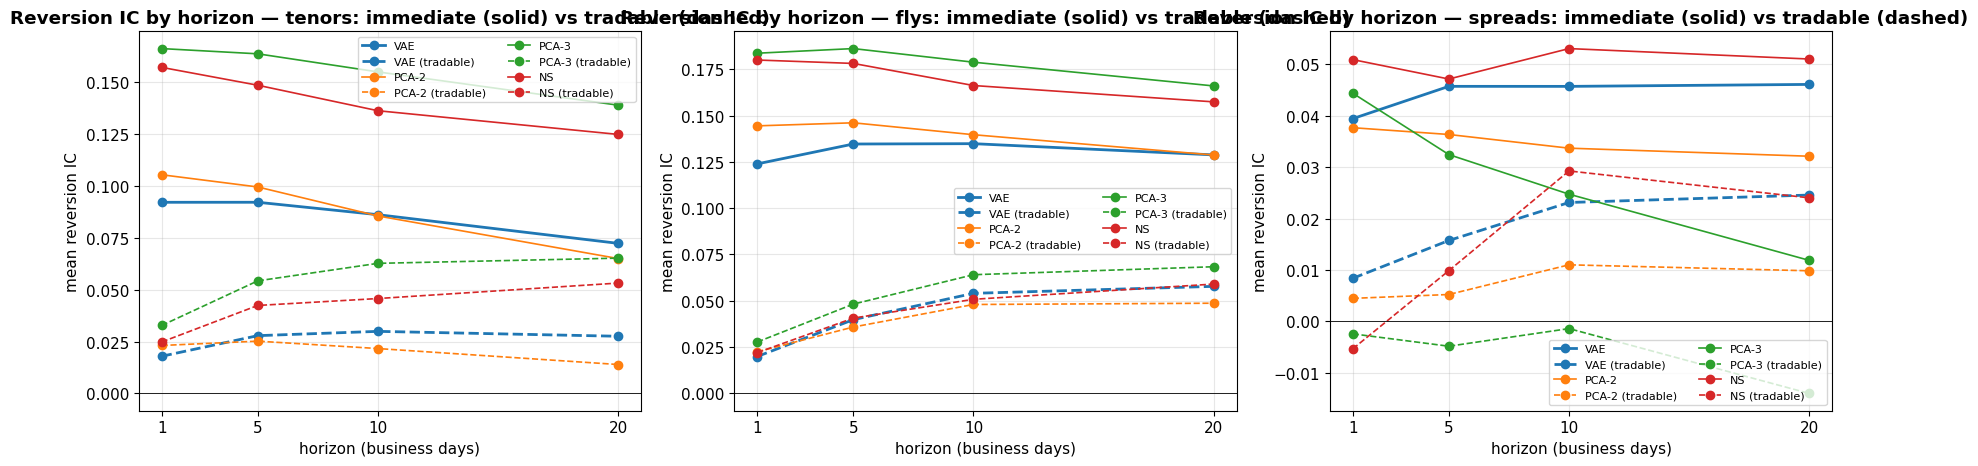

In [6]:
# Hit rate by maturity (h = 10, |z| >= 1), pooled across currencies, and IC term structure by horizon
hit_tab = (IC[(IC.unit == "tenor (tradable)") & (IC.h == 10)].pivot_table(index="model", columns="tenor", values="hit", aggfunc="mean")
           .round(3))
print("Tradable hit rate by maturity (h = 10 days from the fill, signal |z| >= 1):"); print(hit_tab.to_string()); print()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, unit in zip(axes, ["tenor", "fly", "spread"]):
    for k, m in enumerate(SIGNALS):
        col = plt.cm.tab10(k)
        for u, ls in [(unit, "-"), (f"{unit} (tradable)", "--")]:
            s = IC[(IC.unit == u) & (IC.model == m)].groupby("h")["ic"].mean()
            ax.plot(s.index, s.values, "o" + ls, color=col, lw=2 if m == "VAE" else 1.2,
                    label=f"{m}{' (tradable)' if 'tradable' in u else ''}")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(HORIZONS); ax.set_xlabel("horizon (business days)"); ax.set_ylabel("mean reversion IC")
    ax.set_title(f"Reversion IC by horizon — {unit}s: immediate (solid) vs tradable (dashed)", fontweight="bold")
    ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_nb6_ic_horizons.png", dpi=130, bbox_inches="tight"); plt.show()

## 3 — Hedged-package portfolios, P&L decomposition and residual alpha

For every (model, currency, package) we hold a position proportional to the capped signal,
$\text{pos} = d \cdot \operatorname{clip}(z, -3, 3)\cdot \text{TARGET\_VOL}/\sigma(\Delta V)$, with
$d = -1$ for residual (reversion) signals and $d = +1$ for forecast signals; positions are rebalanced
weekly and filled at the next close.

**P&L decomposition** of a package position (long $V = w^\top S$ means payer on legs with $w_k > 0$):
- **rates**: $\text{pos}_{t-1}\,\Delta V_t$ (constant-maturity rate moves);
- **carry**: per unit payer DV01 on tenor $T$, $(f_t - S_{T,t}) / (252\,A_T)$ in bp/day, with $f$ the
  floating index of the swap (overnight rate for OIS, 6M CIBOR/PRIBOR for DKK/CZK) and $A_T$ the annuity;
- **rolldown**: the swap ages by one day, $S(T - 1/252) - S(T)$, by linear interpolation to the next
  shorter node (1Y for the 2Y point);
- **costs**: 0.25 bp per leg per unit DV01 on every change of position.

**Residual alpha.** A package's exposure to the level, slope and curvature factors is known exactly:
$e = w^\top L$ (fit-window loadings of daily changes on its legs). The factor P&L of a position is
therefore $\text{pos}_{t-1}\, e^\top f_t$, with $f_t$ the currency's factor returns, and the
**residual P&L** is the rates P&L minus that factor P&L. Its Sharpe is the strategy's alpha after
removing level/slope/curvature exposure; "factor share" is the fraction of rates-P&L variance that the
factor P&L explains.

In [7]:
def run_strategy(signals_p: dict, direction: int, tc=P["TC_LEG_BP"], scale: dict = None,
                 delay=P["EXEC_DELAY"], rebal=P["REBAL"]):
    """Returns {(c, pkg): DataFrame[rates, carry, roll, cost, total, pos]} over the evaluation window."""
    out = {}
    reb = pd.Series(np.arange(len(dates)) % rebal == 0, index=dates)
    for (c, n), z in signals_p.items():
        p = packages[(c, n)]
        target = direction * z.clip(-P["SIGNAL_CAP"], P["SIGNAL_CAP"]) * P["TARGET_VOL_BP"] / p["vol"]
        if scale is not None:
            target = target * scale[c]
        target = target.where(eval_mask).replace([np.inf, -np.inf], np.nan).fillna(0.0)
        target = target.where(reb).ffill().fillna(0.0)
        held = target.shift(delay).fillna(0.0)                     # position held at close t
        prev = held.shift(1).fillna(0.0)                           # position earning day t
        cost = held.diff().abs().fillna(0.0) * np.abs(p["w"]).sum() * tc
        factor_pnl = prev * (F[c].values @ p["expo"])
        df = pd.DataFrame({"rates": prev * p["dV"], "carry": prev * p["carry"].shift(1), "roll": prev * p["roll"].shift(1),
                           "cost": -cost, "pos": held, "factor": factor_pnl}).fillna(0.0)
        df["idio"] = df["rates"] - df["factor"]
        df["total"] = df[["rates", "carry", "roll", "cost"]].sum(axis=1)
        out[(c, n)] = df.loc[eval_mask]
    return out


def evaluate(res: dict, label: str) -> dict:
    tot = sum(r["total"] for r in res.values()); comp = {k: sum(r[k] for r in res.values()) for k in ["rates", "carry", "roll", "cost"]}
    ann = lambda s: s.mean() * 252
    sharpe = lambda s: s.mean() / s.std() * np.sqrt(252) if s.std() > 0 else 0.0
    turnover = np.mean([r["pos"].diff().abs().sum() / (len(r) / 252) for r in res.values()])
    # residual alpha: rates P&L minus the known factor P&L (pos x exposure x factor returns)
    idio = sum(r["idio"] for r in res.values())
    fshare = np.mean([1 - r["idio"].var() / r["rates"].var() for r in res.values() if r["rates"].var() > 0])
    return {"strategy": label, "net Sharpe": sharpe(tot), "gross Sharpe (rates only)": sharpe(comp["rates"]),
            "total (bp-risk)": tot.sum(), **{f"{k} (bp-risk/yr)": ann(v) for k, v in comp.items()},
            "turnover (units/yr)": turnover, "factor share of rates variance": fshare,
            "residual-alpha Sharpe": sharpe(idio)}


strat = {}
for m in ["VAE", "PCA-2", "PCA-3", "NS"]:
    strat[f"{m} residual"] = run_strategy(SIGNALS[m][1], direction=-1)
# flies only (the truly level+slope-neutral packages) for the main models
for m in ["VAE", "PCA-2", "PCA-3", "NS"]:
    strat[f"{m} residual, flies only"] = run_strategy({k: v for k, v in SIGNALS[m][1].items()
                                                      if packages[k]["kind"] == "fly"}, direction=-1)
port = pd.DataFrame([evaluate(v, k) for k, v in strat.items()]).set_index("strategy")
print(f"Sharpe standard error over {eval_mask.sum()} days ≈ {np.sqrt(252 / eval_mask.sum()):.2f}")
port.round(2)

Sharpe standard error over 735 days ≈ 0.59


,net Sharpe,gross Sharpe (rates only),total (bp-risk),rates (bp-risk/yr),carry (bp-risk/yr),roll (bp-risk/yr),cost (bp-risk/yr),turnover (units/yr),factor share of rates variance,residual-alpha Sharpe
strategy,,,,,,,,,,
VAE residual,-3.36,-0.02,-2371.36,-4.88,-54.74,-70.18,-683.25,29.71,0.56,-0.32
PCA-2 residual,-3.30,-0.34,-2337.04,-73.67,-10.04,-27.14,-690.42,30.06,0.56,-0.17
PCA-3 residual,-3.77,-0.34,-2305.14,-59.12,1.87,6.35,-739.43,32.20,0.55,-0.52
NS residual,-4.03,-0.23,-2456.14,-39.41,-27.37,-34.46,-740.87,32.28,0.55,-0.58
"VAE residual, flies only",-3.80,-0.20,-2086.72,-31.94,-33.55,-41.86,-608.10,43.95,0.30,-0.23
"PCA-2 residual, flies only",-3.82,-0.43,-2094.17,-68.37,-9.75,-23.67,-616.21,44.61,0.30,-0.03
"PCA-3 residual, flies only",-3.81,-0.20,-1938.48,-27.82,-8.01,13.53,-642.32,46.48,0.28,-0.40
"NS residual, flies only",-4.34,-0.64,-2249.10,-91.74,-28.15,-18.04,-633.20,45.83,0.29,-0.61


Net Sharpe vs transaction cost:
       tc 0.0 bp/leg  tc 0.1 bp/leg  tc 0.25 bp/leg  tc 0.5 bp/leg
VAE            -0.59          -1.80           -3.36          -5.00
PCA-2          -0.51          -1.74           -3.30          -4.93
PCA-3          -0.29          -1.91           -3.77          -5.38
NS             -0.60          -2.22           -4.03          -5.54



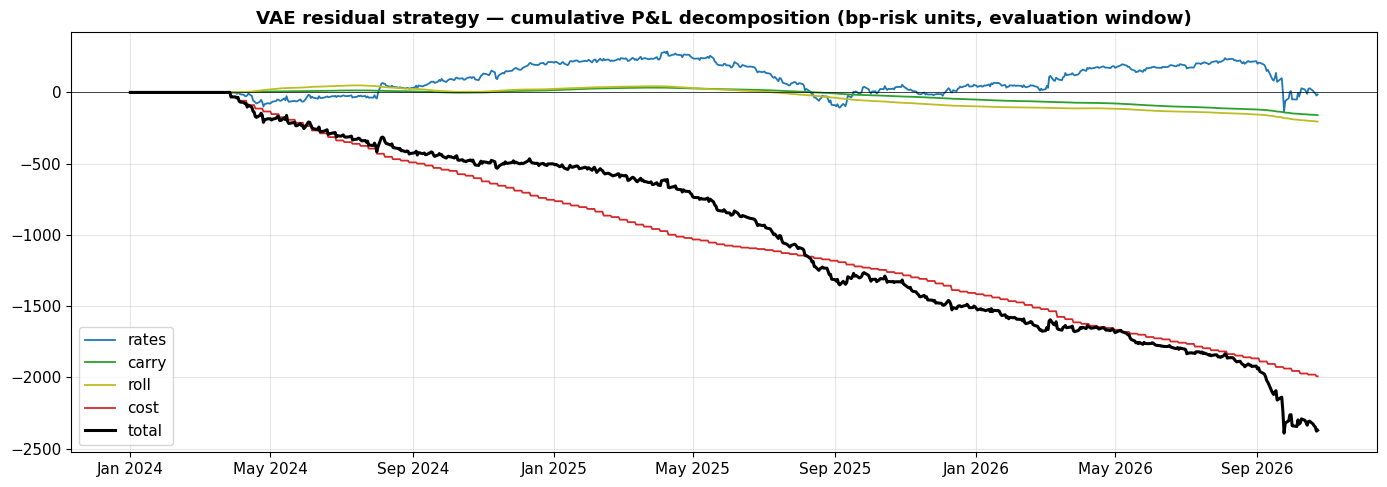

In [8]:
# Cost sensitivity and P&L decomposition chart for the VAE strategy
sens = pd.DataFrame({tc: {m: evaluate(run_strategy(SIGNALS[m][1], -1, tc=tc), m)["net Sharpe"] for m in ["VAE", "PCA-2", "PCA-3", "NS"]}
                     for tc in [0.0, 0.1, 0.25, 0.5]}).round(2)
sens.columns = [f"tc {c} bp/leg" for c in sens.columns]
print("Net Sharpe vs transaction cost:"); print(sens.to_string()); print()

r = strat["VAE residual"]
fig, ax = plt.subplots(figsize=(14, 5))
for k, col in [("rates", "tab:blue"), ("carry", "tab:green"), ("roll", "tab:olive"), ("cost", "tab:red"), ("total", "black")]:
    ax.plot(sum(v[k] for v in r.values()).cumsum(), lw=2.2 if k == "total" else 1.3, color=col, label=k)
ax.axhline(0, color="black", lw=0.5); ax.legend()
ax.set_title("VAE residual strategy — cumulative P&L decomposition (bp-risk units, evaluation window)", fontweight="bold")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_nb6_pnl_decomposition.png", dpi=130, bbox_inches="tight"); plt.show()

## 4 — Regimes: Markov-switching on the VAE latent factors (filtered probabilities only)

For each currency we take the daily change of the post-processed CVAE latent point $z^*$, projected on
its main direction (estimated on the fit window), and fit a **two-state Markov-switching model with
regime-dependent variance** on the **fit window only**. The fitted parameters are then run through the
**filter** over the whole sample: the probability of the high-volatility regime at date $t$ uses
observations up to $t$ only — never smoothed states, which would look into the future. The two states
are a low- and a high-volatility regime; the high-volatility state is not a rare "crisis" state (it
covers 40–70% of days for most currencies).

We then measure, by regime: the reversion IC of the VAE package signals, the speed of mean reversion
of package residuals (AR(1) half-life) and their variance; and we compare the unconditional strategy
with two conditional ones (position × P(low-vol), or trade only when P(low-vol) > 0.5).

In [9]:
p_calm, regime_params = {}, []
for c in CURRENCIES:
    dz = np.diff(z_star[c], axis=0)
    u_dir = np.linalg.eigh(np.cov(dz[fit_mask[1:]].T))[1][:, -1]
    u = pd.Series(dz @ u_dir, index=dates[1:])
    u_fit = u[u.index <= FIT_END]
    scale = u_fit.std()
    mod_fit = MarkovRegression(u_fit.values / scale, k_regimes=2, trend="c", switching_variance=True)
    res_fit = mod_fit.fit(disp=False)
    prm = pd.Series(np.asarray(res_fit.params), index=mod_fit.param_names)
    filt = MarkovRegression(u.values / scale, k_regimes=2, trend="c", switching_variance=True).filter(prm.values)
    probs = np.asarray(filt.filtered_marginal_probabilities)
    sig2 = [prm[f"sigma2[{k}]"] for k in range(2)]
    hi = int(np.argmax(sig2)); calm_k = 1 - hi
    p_calm[c] = pd.Series(np.r_[np.nan, 1 - probs[:, hi]], index=dates)
    p_stay = prm["p[0->0]"] if calm_k == 0 else 1 - prm["p[1->0]"]
    regime_params.append({"currency": c, "vol ratio high/low": np.sqrt(max(sig2) / min(sig2)),
                          "P(stay low-vol)": p_stay,
                          "high-vol share (fit)": (1 - p_calm[c][fit_mask]).mean(),
                          "high-vol share (evaluation)": (1 - p_calm[c][eval_mask]).mean()})
p_calm = pd.DataFrame(p_calm)
print("Markov-switching parameters per currency (estimated on 2020–2023; filtered probabilities in evaluation):")
pd.DataFrame(regime_params).set_index("currency").round(2)

Markov-switching parameters per currency (estimated on 2020–2023; filtered probabilities in evaluation):


,vol ratio high/low,P(stay low-vol),high-vol share (fit),high-vol share (evaluation)
currency,,,,
AUD,2.78,0.99,0.63,0.39
CAD,2.59,0.99,0.69,0.66
CHF,3.44,0.99,0.45,0.35
CZK,2.39,0.94,0.64,0.42
DKK,3.46,0.99,0.61,0.61
EUR,3.44,0.99,0.61,0.56
GBP,3.54,0.98,0.56,0.38
JPY,3.43,0.97,0.41,0.68
USD,3.78,0.99,0.63,0.63


In [10]:
# IC, mean-reversion speed and residual variance by regime (VAE package signals)
rows = []
sig_p = SIGNALS["VAE"][1]
for (c, n), z in sig_p.items():
    R = resid["VAE"][c][packages[(c, n)]["legs"]] @ packages[(c, n)]["w"]
    calm = p_calm[c] > 0.5
    for lab, mask in [("low-vol", calm), ("high-vol", ~calm)]:
        m_ = mask & pd.Series(eval_mask, index=dates)
        for h in (5, 10):
            ic, t, hit, nobs = nw_ic(z.where(m_), fut_pkg_tr[(c, n, h)], h)
            rows.append(dict(regime=lab, metric=f"tradable reversion IC h={h}", value=ic))
        x, y = R.shift(0)[m_], R.shift(-1)[m_]
        d = pd.concat([x, y], axis=1).dropna()
        if len(d) > 30:
            phi = np.polyfit(d.iloc[:, 0], d.iloc[:, 1], 1)[0]
            rows.append(dict(regime=lab, metric="AR(1) phi of residual", value=phi))
            rows.append(dict(regime=lab, metric="half-life (days)", value=np.log(0.5) / np.log(phi) if 0 < phi < 1 else np.nan))
        rows.append(dict(regime=lab, metric="residual daily-change std (bp)", value=R.diff()[m_].std()))
reg_tab = pd.DataFrame(rows).groupby(["metric", "regime"])["value"].median().unstack().round(3)
print("By regime (median across currency × package):"); print(reg_tab.to_string()); print()

cond = {"VAE unconditional": strat["VAE residual"],
        "VAE × P(low-vol)": run_strategy(sig_p, -1, scale={c: p_calm[c].fillna(0) for c in CURRENCIES}),
        "VAE only if P(low-vol) > 0.5": run_strategy(sig_p, -1, scale={c: (p_calm[c] > 0.5).astype(float) for c in CURRENCIES})}
reg_port = pd.DataFrame([evaluate(v, k) for k, v in cond.items()]).set_index("strategy")
# performance of the unconditional strategy split by regime
tot = sum(r["total"] for r in strat["VAE residual"].values())
# regime known at the decision date: P&L of day t comes from a decision at t - EXEC_DELAY - 1
lag = P["EXEC_DELAY"] + 1
low_share = pd.concat([(p_calm[c] > 0.5) for c in CURRENCIES], axis=1).mean(axis=1).shift(lag).loc[tot.index]
split = {"decided mostly in low-vol": tot[low_share >= 0.5], "decided mostly in high-vol": tot[low_share < 0.5]}
print("Unconditional VAE strategy, P&L by regime at the decision date (bp-risk/day):",
      {k: f"mean {v.mean():+.3f}, days {len(v)}" for k, v in split.items()})
reg_port[["net Sharpe", "total (bp-risk)", "turnover (units/yr)", "residual-alpha Sharpe"]].round(2)

By regime (median across currency × package):
regime                          high-vol  low-vol
metric                                           
AR(1) phi of residual              0.981    0.992
half-life (days)                  36.455   68.697
residual daily-change std (bp)     1.203    0.759
tradable reversion IC h=10         0.060    0.031
tradable reversion IC h=5          0.037    0.008



Unconditional VAE strategy, P&L by regime at the decision date (bp-risk/day): {'decided mostly in low-vol': 'mean -3.886, days 328', 'decided mostly in high-vol': 'mean -2.694, days 407'}


,net Sharpe,total (bp-risk),turnover (units/yr),residual-alpha Sharpe
strategy,,,,
VAE unconditional,-3.36,-2371.36,29.71,-0.32
VAE × P(low-vol),-4.78,-1967.26,25.69,-0.57
VAE only if P(low-vol) > 0.5,-4.76,-2129.51,27.84,-0.50


## 5 — Training objective: reconstruction vs prediction vs multitask

Same CVAE encoder (two latent factors, currency label), three objectives, all trained on the fit window:

| Model | Loss |
|---|---|
| **REC** (the VAE above) | reconstruction of today's curve |
| **PRED** | prediction of the standardised future curve moves at 5 and 20 days (prediction head on $z$ and the currency label) |
| **MTL** | reconstruction loss divided by $10^{-5}$ (so both terms are of order 1 at convergence) + prediction |

Prediction targets only use dates whose horizon ends inside the fit window. Linear benchmarks: **ridge**
regression of future moves on today's curve (per currency, α = 10), **DNS** (VAR(1) on NS betas) and
the random walk (zero forecast). Metrics: evaluation-period reconstruction RMSE, out-of-sample $R^2$
against the random walk, IC of predicted vs realised package moves, and the same portfolio engine as §3
with the forecast as signal (direction +1).

In [11]:
H = P["PRED_H"]; hmax = max(H)
dS_future = {c: np.concatenate([((curves[c].shift(-h) - curves[c]) * BP).values for h in H], axis=1) for c in CURRENCIES}
target_ok = dates <= dates[fit_mask][-hmax - 1]                    # horizon ends inside the fit window
Tfit = np.vstack([dS_future[c][target_ok] for c in CURRENCIES])
t_mu, t_sd = Tfit.mean(0), Tfit.std(0)
X_tr = torch.from_numpy(np.vstack([normalize(curves[c].values[target_ok]) for c in CURRENCIES]).astype(np.float32))
Y_tr = torch.cat([one_hot(c, int(target_ok.sum())) for c in CURRENCIES])
T_tr = torch.from_numpy(((Tfit - t_mu) / t_sd).astype(np.float32))

heads = {}
for name, (rec_, prd_) in {"PRED": (False, True), "MTL": (True, True)}.items():
    path = RES_DIR / (f"nb6_{name.lower()}_fit_{FIT_END.date()}_{N_CCY}ccy_{P['PRED_EPOCHS']}ep_"
                      f"rs{P['MTL_REC_SCALE']:g}_w{P['MTL_WEIGHT']:g}_h{'-'.join(map(str, P['PRED_H']))}.pt")
    m = MultiHeadCVAE(recon=rec_, pred=prd_)
    if path.exists():
        m.load_state_dict(torch.load(path)); m.eval(); print(f"{name}: loaded {path}")
    else:
        print(f"{name}: training ({len(X_tr)} samples)…"); torch.manual_seed(SEED); t0 = time.time()
        train_model(m, X_tr, Y_tr, T_tr, n_epochs=P["PRED_EPOCHS"]); torch.save(m.state_dict(), path)
        print(f"{name}: {(time.time() - t0) / 60:.1f} min")
    heads[name] = m

# forecasts of future moves (bp), per currency: dict[model][c] -> (T, 7*len(H))
fc = {k: {} for k in ["PRED", "MTL", "Ridge", "DNS"]}
rec_rmse = {}
for c in CURRENCIES:
    x = torch.from_numpy(normalize(curves[c].values).astype(np.float32)); y = one_hot(c, len(x))
    for name, m in heads.items():
        with torch.no_grad():
            rec, prd, mu, _ = m(x, y)
        fc[name][c] = prd.numpy() * t_sd + t_mu
        if rec is not None:
            rec_rmse.setdefault("MTL", {})[c] = np.sqrt(((denormalize(rec.numpy()) - curves[c].values) ** 2).mean(1))[eval_mask].mean() * BP
    with torch.no_grad():
        rec0, _, _, _ = cvae(x, y)
    rec_rmse.setdefault("REC (no post-proc.)", {})[c] = np.sqrt(((denormalize(rec0.numpy()) - curves[c].values) ** 2).mean(1))[eval_mask].mean() * BP
    # ridge: future moves on today's curve
    Xc = curves[c].values * BP; ok = target_ok
    xm, xs = Xc[ok].mean(0), Xc[ok].std(0); Z = (Xc - xm) / xs
    Yc = dS_future[c]; ym = Yc[ok].mean(0)
    coef = np.linalg.solve(Z[ok].T @ Z[ok] + P["RIDGE_ALPHA"] * np.eye(7), Z[ok].T @ (Yc[ok] - ym))
    fc["Ridge"][c] = Z @ coef + ym
    # DNS: h-step VAR(1) forecast of the betas, factor dynamics only
    A, c0 = var1[c]["A"], var1[c]["c"]
    mu_b = np.linalg.solve(np.eye(3) - A, c0)
    fc["DNS"][c] = np.concatenate([((mu_b + (betas[c] - mu_b) @ np.linalg.matrix_power(A, h).T) - betas[c]) @ B_NS.T * BP
                                   for h in H], axis=1)

# out-of-sample R^2 vs random walk, pooled over currencies and tenors
r2 = {}
for name in fc:
    for j, h in enumerate(H):
        num = den = 0.0
        for c in CURRENCIES:
            yv = dS_future[c][:, 7 * j:7 * (j + 1)]; f_ = fc[name][c][:, 7 * j:7 * (j + 1)]
            ok = eval_mask & np.isfinite(yv).all(1)
            num += ((yv[ok] - f_[ok]) ** 2).sum(); den += (yv[ok] ** 2).sum()
        r2[(name, h)] = 1 - num / den
print("Evaluation reconstruction RMSE (bp, encoder mean, no post-processing):",
      {k: round(np.mean(list(v.values())), 2) for k, v in rec_rmse.items()})
pd.Series(r2).unstack().rename(columns=lambda h: f"OOS R² vs random walk, h={h}").round(4)

PRED: training (7587 samples)…
  epoch     1  loss 1.015e+00


  epoch  1000  loss 7.429e-01


  epoch  2000  loss 6.760e-01


  epoch  3000  loss 6.444e-01
PRED: 2.7 min
MTL: training (7587 samples)…
  epoch     1  loss 4.478e+04


  epoch  1000  loss 2.748e+00


  epoch  2000  loss 2.351e+00


  epoch  3000  loss 2.084e+00
MTL: 2.7 min
Evaluation reconstruction RMSE (bp, encoder mean, no post-processing): {'MTL': np.float64(8.25), 'REC (no post-proc.)': np.float64(8.93)}


,"OOS R² vs random walk, h=5","OOS R² vs random walk, h=20"
DNS,-1.1319,-3.6582
MTL,-2.7135,-11.5005
PRED,-4.0313,-8.6158
Ridge,-0.4782,-2.2349


In [12]:
# Forecast signals for packages: predicted package move w . dS_hat (h = 5), causal z-score, direction +1
def forecast_signals(name, h=5):
    j = H.index(h); out = {}
    for c in CURRENCIES:
        f_ = pd.DataFrame(fc[name][c][:, 7 * j:7 * (j + 1)], index=dates, columns=TENORS)
        for n, _ in PKG_SPECS:
            p = packages[(c, n)]
            out[(c, n)] = zscore(f_[p["legs"]] @ p["w"])
    return out


FSIG = {name: forecast_signals(name) for name in fc}                 # 5-day forecasts (used for trading)
FSIG20 = {name: forecast_signals(name, h=20) for name in fc}         # 20-day forecasts (for the 20-day IC)
rows = []
for name in fc:
    for h, sig in ((5, FSIG[name]), (20, FSIG20[name])):
        for (c, n), s in sig.items():
            ic, t, hit, nobs = nw_ic(-s, fut_pkg_tr[(c, n, h)], h)  # forecast, tradable: positive IC = forecast right
            rows.append(dict(model=name, h=h, ic=ic, t=t))
fic = pd.DataFrame(rows).groupby(["model", "h"]).agg(mean_IC=("ic", "mean"), share_positive=("ic", lambda x: (x > 0).mean()),
                                                     median_NW_t=("t", "median")).round(3)
print("Tradable forecast IC on packages (move from the fill; positive = predicted direction right). The signal is the\n"
      "z-scored forecast (its trailing mean removed), whereas the R² above uses the raw forecast."); print(fic.to_string()); print()

for name in FSIG:
    strat[f"{name} forecast"] = run_strategy(FSIG[name], direction=+1)
obj = pd.DataFrame([evaluate(strat[k], k) for k in ["VAE residual", "PRED forecast", "MTL forecast", "Ridge forecast",
                                                     "DNS forecast"]]).set_index("strategy")
obj[["net Sharpe", "gross Sharpe (rates only)", "total (bp-risk)", "turnover (units/yr)", "residual-alpha Sharpe"]].round(2)

Tradable forecast IC on packages (move from the fill; positive = predicted direction right). The signal is the
z-scored forecast (its trailing mean removed), whereas the R² above uses the raw forecast.
          mean_IC  share_positive  median_NW_t
model h                                       
DNS   5     0.018           0.578        0.369
      20    0.019           0.511        0.041
MTL   5    -0.000           0.556        0.130
      20   -0.001           0.511        0.073
PRED  5    -0.044           0.289       -0.614
      20   -0.087           0.311       -0.768
Ridge 5     0.034           0.578        0.348
      20    0.044           0.511        0.016



,net Sharpe,gross Sharpe (rates only),total (bp-risk),turnover (units/yr),residual-alpha Sharpe
strategy,,,,,
VAE residual,-3.36,-0.02,-2371.36,29.71,-0.32
PRED forecast,-3.45,-1.48,-2323.54,29.63,-0.60
MTL forecast,-2.48,-0.55,-1523.92,26.26,-0.52
Ridge forecast,-2.11,0.00,-1752.70,28.78,-0.03
DNS forecast,-2.22,-0.26,-1940.43,30.70,-0.27


## 6 — Summary and answer to the research question

In [13]:
all_rows = [evaluate(v, k) for k, v in strat.items()] + \
           [evaluate(v, k) for k, v in cond.items() if k != "VAE unconditional"]
active_days = int((sum(r["pos"].abs() for r in strat["VAE residual"].values()) > 0).sum())
summary = pd.DataFrame(all_rows).drop_duplicates("strategy").set_index("strategy")
pk = IC[IC.unit.isin(["fly", "spread"])]; pkt = IC[IC.unit.isin(["fly (tradable)", "spread (tradable)"])]
ic5_imm = pk[pk.h == 5].groupby("model")["ic"].mean()
ic5 = pkt[pkt.h == 5].groupby("model")["ic"].mean()
ic20 = pkt[pkt.h == 20].groupby("model")["ic"].mean()
ic5_fly = IC[(IC.unit == "fly (tradable)") & (IC.h == 5)].groupby("model")["ic"].mean()
hit10 = pkt[pkt.h == 10].groupby("model")["hit"].mean()
fic5 = fic.xs(5, level="h")["mean_IC"]; fic20 = fic.xs(20, level="h")["mean_IC"]
def model_of(label):
    """Signal model of a plain residual/forecast strategy; None for derived variants (same signal as their base)."""
    return label.split()[0] if label.endswith(" residual") or label.endswith(" forecast") else None


summary["immediate IC h=5"] = [ic5_imm.get(model_of(k), np.nan) for k in summary.index]
summary["tradable IC h=5"] = [ic5.get(model_of(k), fic5.get(model_of(k), np.nan)) for k in summary.index]
summary["tradable IC h=5, flies"] = [ic5_fly.get(model_of(k), np.nan) for k in summary.index]
summary["tradable IC h=20"] = [ic20.get(model_of(k), fic20.get(model_of(k), np.nan)) for k in summary.index]
summary["tradable hit rate h=10"] = [hit10.get(model_of(k), np.nan) for k in summary.index]
cols = ["immediate IC h=5", "tradable IC h=5", "tradable IC h=5, flies", "tradable IC h=20", "tradable hit rate h=10",
        "net Sharpe", "gross Sharpe (rates only)",
        "carry (bp-risk/yr)", "roll (bp-risk/yr)", "cost (bp-risk/yr)", "turnover (units/yr)",
        "factor share of rates variance", "residual-alpha Sharpe"]
print(f"Evaluation window {dates[eval_mask][0].date()} → {dates[-1].date()} ({eval_mask.sum()} days, of which {active_days} "
      f"with positions after the z-score warm-up); Sharpe SE ≈ {np.sqrt(252 / active_days):.2f}. "
      "Derived variants (flies only, regime-conditioned) show no IC: they use the same signal as their base model.")
summary[cols].round(3)

Evaluation window 2024-01-01 → 2026-10-23 (735 days, of which 672 with positions after the z-score warm-up); Sharpe SE ≈ 0.61. Derived variants (flies only, regime-conditioned) show no IC: they use the same signal as their base model.


,immediate IC h=5,tradable IC h=5,"tradable IC h=5, flies",tradable IC h=20,tradable hit rate h=10,net Sharpe,gross Sharpe (rates only),carry (bp-risk/yr),roll (bp-risk/yr),cost (bp-risk/yr),turnover (units/yr),factor share of rates variance,residual-alpha Sharpe
strategy,,,,,,,,,,,,,
VAE residual,0.099,0.030,0.040,0.045,0.495,-3.355,-0.022,-54.736,-70.179,-683.245,29.711,0.561,-0.320
PCA-2 residual,0.102,0.024,0.036,0.033,0.491,-3.302,-0.342,-10.038,-27.141,-690.422,30.063,0.562,-0.168
PCA-3 residual,0.125,0.027,0.048,0.035,0.493,-3.772,-0.340,1.873,6.347,-739.432,32.204,0.547,-0.518
NS residual,0.126,0.028,0.041,0.045,0.503,-4.029,-0.232,-27.368,-34.460,-740.871,32.283,0.553,-0.583
"VAE residual, flies only",NaN,NaN,NaN,NaN,NaN,-3.797,-0.198,-33.549,-41.855,-608.097,43.951,0.300,-0.231
"PCA-2 residual, flies only",NaN,NaN,NaN,NaN,NaN,-3.822,-0.432,-9.749,-23.665,-616.214,44.609,0.301,-0.031
"PCA-3 residual, flies only",NaN,NaN,NaN,NaN,NaN,-3.815,-0.197,-8.013,13.527,-642.317,46.479,0.281,-0.403
"NS residual, flies only",NaN,NaN,NaN,NaN,NaN,-4.343,-0.637,-28.146,-18.037,-633.198,45.830,0.286,-0.606
PRED forecast,NaN,-0.044,NaN,-0.087,NaN,-3.454,-1.475,92.680,95.595,-681.146,29.626,0.548,-0.603


In [14]:
vae_ic = ic5.get("VAE")
se = np.sqrt(252 / active_days)
v = summary.loc["VAE residual"]
print("ANSWER (computed):")
print(f"1. Do VAE residuals mean-revert in price? Package reversion IC at 5 days: immediate {ic5_imm.get('VAE'):+.3f}, "
      f"tradable {vae_ic:+.3f} (PCA-2 {ic5_imm.get('PCA-2'):+.3f} / {ic5.get('PCA-2'):+.3f}, PCA-3 {ic5_imm.get('PCA-3'):+.3f} / "
      f"{ic5.get('PCA-3'):+.3f}, NS {ic5_imm.get('NS'):+.3f} / {ic5.get('NS'):+.3f}).")
print(f"2. Is that tradable? VAE residual strategy: net Sharpe {v['net Sharpe']:+.2f}, gross (rates) {v['gross Sharpe (rates only)']:+.2f}, "
      f"residual-alpha Sharpe {v['residual-alpha Sharpe']:+.2f} (SE ≈ {se:.2f}).")
best = summary["net Sharpe"].idxmax(); bs = summary.loc[best, "net Sharpe"]
verdict = ("not distinguishable from zero" if abs(bs) < 2 * se else
           ("significantly positive" if bs > 0 else "significantly negative"))
print(f"3. Best net Sharpe across all {len(summary)} variants: {best} ({bs:+.2f}), {verdict} at ~2 standard errors "
      f"(no correction for having compared {len(summary)} correlated variants). "
      f"Best gross (rates-only) Sharpe: {summary['gross Sharpe (rates only)'].max():+.2f}.")
print(f"4. Regime conditioning: unconditional {reg_port.loc['VAE unconditional', 'net Sharpe']:+.2f} vs "
      f"× P(low-vol) {reg_port.loc['VAE × P(low-vol)', 'net Sharpe']:+.2f} vs low-vol only "
      f"{reg_port.loc['VAE only if P(low-vol) > 0.5', 'net Sharpe']:+.2f}.")
print(f"5. Training objective: REC residual {summary.loc['VAE residual', 'net Sharpe']:+.2f}, PRED {summary.loc['PRED forecast', 'net Sharpe']:+.2f}, "
      f"MTL {summary.loc['MTL forecast', 'net Sharpe']:+.2f}, Ridge {summary.loc['Ridge forecast', 'net Sharpe']:+.2f}, "
      f"DNS {summary.loc['DNS forecast', 'net Sharpe']:+.2f} (net Sharpe).")

ANSWER (computed):
1. Do VAE residuals mean-revert in price? Package reversion IC at 5 days: immediate +0.099, tradable +0.030 (PCA-2 +0.102 / +0.024, PCA-3 +0.125 / +0.027, NS +0.126 / +0.028).
2. Is that tradable? VAE residual strategy: net Sharpe -3.36, gross (rates) -0.02, residual-alpha Sharpe -0.32 (SE ≈ 0.61).
3. Best net Sharpe across all 14 variants: Ridge forecast (-2.11), significantly negative at ~2 standard errors (no correction for having compared 14 correlated variants). Best gross (rates-only) Sharpe: +0.00.
4. Regime conditioning: unconditional -3.36 vs × P(low-vol) -4.78 vs low-vol only -4.76.
5. Training objective: REC residual -3.36, PRED -3.45, MTL -2.48, Ridge -2.11, DNS -2.22 (net Sharpe).


### Interpretation guide
- **Residual vs model error.** A residual is a *tradable* mispricing only if it predicts a hedged move
  of the market in the reverting direction **from the moment we can trade** (tradable IC, §2) and that
  prediction survives costs, carry and factor exposure (§3). A positive immediate IC with a near-zero
  tradable IC means the "reversion" happens on the next print (quote noise) and cannot be captured. If the residual "reverts" mainly because the model's fair value moves toward the market
  — typical when an out-of-sample model drifts — the IC on hedged *price* moves is small and the
  strategy does not earn it.
- **VAE vs linear models.** The VAE adds value only if its IC and residual alpha exceed those of PCA-3
  and NS built and traded identically; otherwise its nonlinearity buys reconstruction accuracy, not
  information about future moves.
- **Reconstruction vs prediction.** Comparing REC, PRED and MTL tests directly whether "the best RMSE
  is not the best model for trading".
- All Sharpe ratios have a standard error of about 0.6–0.65 (on the days with positions), before any
  correction for the number of variants compared. t-statistics pool currency × package series as if
  they were independent, which overstates significance.
- Benchmarks: the DNS VAR(1) is close to a unit root (largest eigenvalue ≈ 0.996–0.999), so its long-run
  mean is poorly identified and it is a weak forecaster; ridge is the stronger linear benchmark.